# Brain Stroke Risk: Livelihood & Health KPIs
## Course: Intro to Data Science – Project Work

**Project Objective**

Identify how livelihood factors and health KPIs influence brain stroke risk, and derive actionable insights for prevention.

**Stakeholders**

- Public health planners
- Hospital management & clinicians
- Insurance / policy designers

**Success Criteria**

- Clear, interpretable model of stroke risk
- Evidence‑based insights on key livelihood & health drivers
- Visual, decision‑oriented summary for non‑technical decision‑makers


## PHASE 1 — BUSINESS UNDERSTANDING (CRISP‑DM)

- **Business problem:** Stroke is a major cause of disability and death. We want to understand how livelihood conditions and health KPIs jointly affect stroke risk.
- **Analytic goal:** Build an interpretable classification model (stroke: 0/1) and quantify the impact of livelihood and health factors.
- **Project constraints:** Tabular, observational dataset; imbalanced target; no causal inference, only association.
- **Success metrics:**
  - Model: ROC‑AUC, recall for stroke class.
  - Business: Clear ranking of risk factors and practical recommendations.



## PHASE 2 — DATA UNDERSTANDING

In [2]:
## PHASE 2 — DATA UNDERSTANDING

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("healthcare-dataset-stroke-data.csv")

print("Shape:", df.shape)


Shape: (5110, 12)


In [3]:
display(df.head())


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [4]:
df.info()



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df.describe(include="all")

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110.000000,5110,5110.000000,5110.000000,5110.000000,5110,5110,5110,5110.000000,4909.000000,5110,5110.000000
unique,NaN,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,NaN,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,NaN,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,36517.829354,NaN,43.226614,0.097456,0.054012,NaN,NaN,NaN,106.147677,28.893237,NaN,0.048728
std,21161.721625,NaN,22.612647,0.296607,0.226063,NaN,NaN,NaN,45.283560,7.854067,NaN,0.215320
min,67.000000,NaN,0.080000,0.000000,0.000000,NaN,NaN,NaN,55.120000,10.300000,NaN,0.000000
25%,17741.250000,NaN,25.000000,0.000000,0.000000,NaN,NaN,NaN,77.245000,23.500000,NaN,0.000000
50%,36932.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN,NaN,91.885000,28.100000,NaN,0.000000
75%,54682.000000,NaN,61.000000,0.000000,0.000000,NaN,NaN,NaN,114.090000,33.100000,NaN,0.000000


In [6]:
print("Missing values:\n", df.isna().sum())


Missing values:
 id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64


In [7]:
print("Duplicated rows:", df.duplicated().sum())


Duplicated rows: 0


In [8]:
df["stroke"].value_counts(normalize=True)

stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64

### 2.1 Dataset selection & justification

- **Dataset:** Public “healthcare-dataset-stroke-data” (demographics, lifestyle, clinical KPIs, stroke label).
- **Why appropriate?**
  - Contains both **livelihood** (work_type, Residence_type, ever_married, smoking_status) and **health** KPIs (age, hypertension, heart_disease, avg_glucose_level, bmi).
  - Directly supports the objective: predicting and explaining stroke risk.
- **Initial observations**
  - Strong class imbalance (few stroke cases).
  - `bmi` has missing values.
  - `smoking_status` contains “Unknown”.


## PHASE 3 — DATA PREPARATION

### 3.1 Handle BMI missing values
##### (best practice: median imputation)


In [9]:
# Convert BMI to numeric and impute
df["bmi"] = df["bmi"].replace("N/A", np.nan).astype(float)
print("BMI missing before:", df["bmi"].isna().sum())

BMI missing before: 201


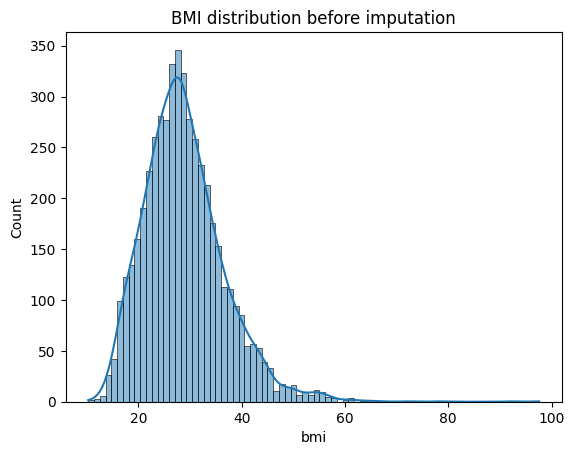

In [10]:
plt.figure()
sns.histplot(df["bmi"], kde=True)
plt.title("BMI distribution before imputation")
plt.show()

In [11]:

bmi_median = df["bmi"].median()
df["bmi"] = df["bmi"].fillna(bmi_median)
print("BMI missing after:", df["bmi"].isna().sum())

BMI missing after: 0


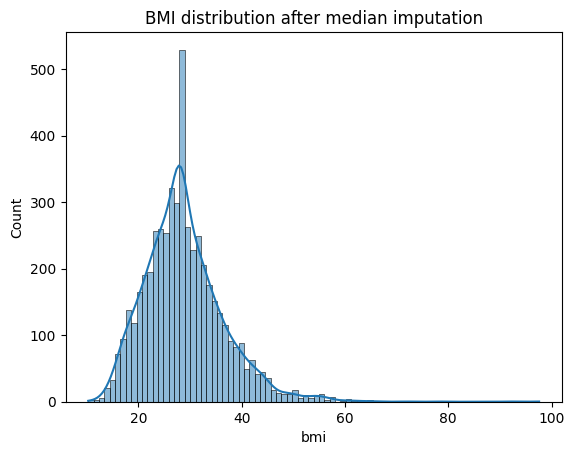

In [12]:
plt.figure()
sns.histplot(df["bmi"], kde=True)
plt.title("BMI distribution after median imputation")
plt.show()


### 3.2 Outlier handling (avg_glucose_level & BMI)


In [13]:
before_stats = {
    "glucose_mean": df["avg_glucose_level"].mean(),
    "glucose_median": df["avg_glucose_level"].median(),
    "glucose_mode": df["avg_glucose_level"].mode()[0],

    "bmi_mean": df["bmi"].mean(),
    "bmi_median": df["bmi"].median(),
    "bmi_mode": df["bmi"].mode()[0]
}

print("=== BEFORE CAPPING ===")
for k, v in before_stats.items():
    print(f"{k}: {v}")

=== BEFORE CAPPING ===
glucose_mean: 106.1476771037182
glucose_median: 91.88499999999999
glucose_mode: 93.88
bmi_mean: 28.862035225048924
bmi_median: 28.1
bmi_mode: 28.1


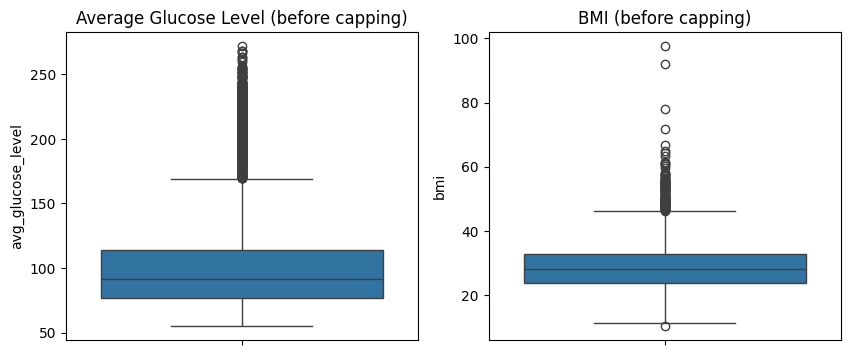

In [14]:
# Visualize outliers
fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.boxplot(y=df["avg_glucose_level"], ax=axes[0])
axes[0].set_title("Average Glucose Level (before capping)")
sns.boxplot(y=df["bmi"], ax=axes[1])
axes[1].set_title("BMI (before capping)")
plt.show()


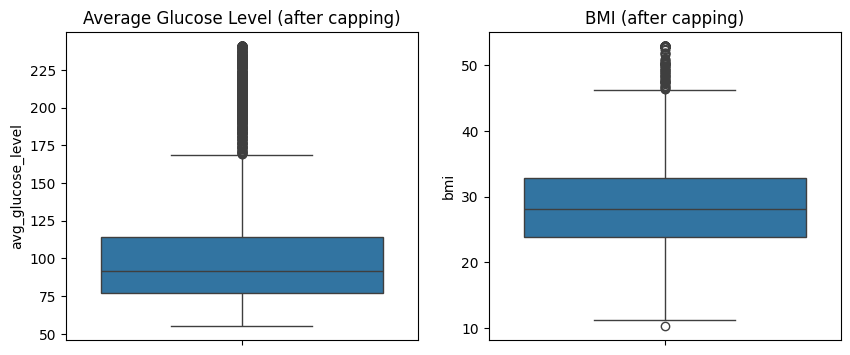

In [15]:
# Cap at 99th percentile
glucose_cap = df["avg_glucose_level"].quantile(0.99)
bmi_cap = df["bmi"].quantile(0.99)

df["avg_glucose_level"] = np.where(df["avg_glucose_level"] > glucose_cap,
                                   glucose_cap,
                                   df["avg_glucose_level"])
df["avg_glucose_level_capped"] = df["avg_glucose_level"]  # Store capped values for later comparison

df["bmi"] = np.where(df["bmi"] > bmi_cap, bmi_cap, df["bmi"])
df["bmi_capped"] = df["bmi"]  # Store capped values for later comparison

fig, axes = plt.subplots(1, 2, figsize=(10,4))
sns.boxplot(y=df["avg_glucose_level"], ax=axes[0])
axes[0].set_title("Average Glucose Level (after capping)")
sns.boxplot(y=df["bmi"], ax=axes[1])
axes[1].set_title("BMI (after capping)")
plt.show()

In [16]:
after_stats = {
    "glucose_mean_after": df["avg_glucose_level_capped"].mean(),
    "glucose_median_after": df["avg_glucose_level_capped"].median(),
    "glucose_mode_after": df["avg_glucose_level_capped"].mode()[0],

    "bmi_mean_after": df["bmi_capped"].mean(),
    "bmi_median_after": df["bmi_capped"].median(),
    "bmi_mode_after": df["bmi_capped"].mode()[0]
}

print("\n=== AFTER CAPPING (99th Percentile) ===")
for k, v in after_stats.items():
    print(f"{k}: {v}")


=== AFTER CAPPING (99th Percentile) ===
glucose_mean_after: 106.04152571428571
glucose_median_after: 91.88499999999999
glucose_mode_after: 240.7082
bmi_mean_after: 28.800299804305286
bmi_median_after: 28.1
bmi_mode_after: 28.1


### 3.3 Encode categorical variables
- We use one‑hot encoding with `drop_first=True` to avoid multicollinearity.


In [17]:
categorical_cols = ["gender", "ever_married", "work_type",
                    "Residence_type", "smoking_status"]

df_encoded = pd.get_dummies(df, columns=categorical_cols)

df_encoded.head()


,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,avg_glucose_level_capped,bmi_capped,gender_Female,gender_Male,gender_Other,ever_married_No,ever_married_Yes,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Rural,Residence_type_Urban,smoking_status_Seasonal,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,9046,67.0,0,1,228.69,36.6,1,228.69,36.6,False,True,False,False,True,False,False,True,False,False,False,True,False,True,False,False
1,51676,61.0,0,0,202.21,28.1,1,202.21,28.1,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False
2,31112,80.0,0,1,105.92,32.5,1,105.92,32.5,False,True,False,False,True,False,False,True,False,False,True,False,False,False,True,False
3,60182,49.0,0,0,171.23,34.4,1,171.23,34.4,True,False,False,False,True,False,False,True,False,False,False,True,False,False,False,True
4,1665,79.0,1,0,174.12,24.0,1,174.12,24.0,True,False,False,False,True,False,False,False,True,False,True,False,False,False,True,False


### 3.4 Define feature groups

**Livelihood KPIs**

- work_type
- Residence_type
- ever_married

**Health KPIs**

- age
- hypertension
- heart_disease
- avg_glucose_level
- bmi
- smoking_status


In [30]:
livelihood_cols = [
    "work_type_Private",
    "work_type_Self-employed",
    "Residence_type_Urban",
    "ever_married_Yes"
]

health_cols = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi",
    "smoking_status_smokes",
    "smoking_status_Seasonal",
    "smoking_status_formerly smoked",
    "smoking_status_never smoked"
]



target = "stroke"

X = df_encoded[livelihood_cols + health_cols]
y = df_encoded[target]


## PHASE 4 — EXPLORATORY DATA ANALYSIS (EDA)

### 4.1 Age and Stroke Rate


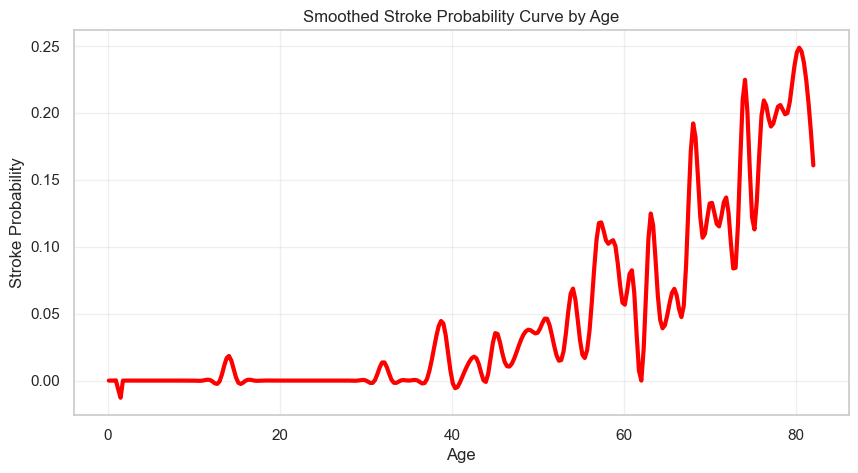

In [31]:
# Age vs Stroke Probability — Smoothed Spline Curve

from scipy.interpolate import make_interp_spline
import numpy as np

age_means = df.groupby('age')['stroke'].mean().reset_index()
x = age_means['age']
y = age_means['stroke']

X_smooth = np.linspace(x.min(), x.max(), 300)
Y_smooth = make_interp_spline(x, y)(X_smooth)

plt.figure(figsize=(10,5))
plt.plot(X_smooth, Y_smooth, color='red', linewidth=3)
plt.title("Smoothed Stroke Probability Curve by Age")
plt.xlabel("Age")
plt.ylabel("Stroke Probability")
plt.grid(alpha=0.3)
plt.show()


### 4.2 Stroke rate by livelihood factors

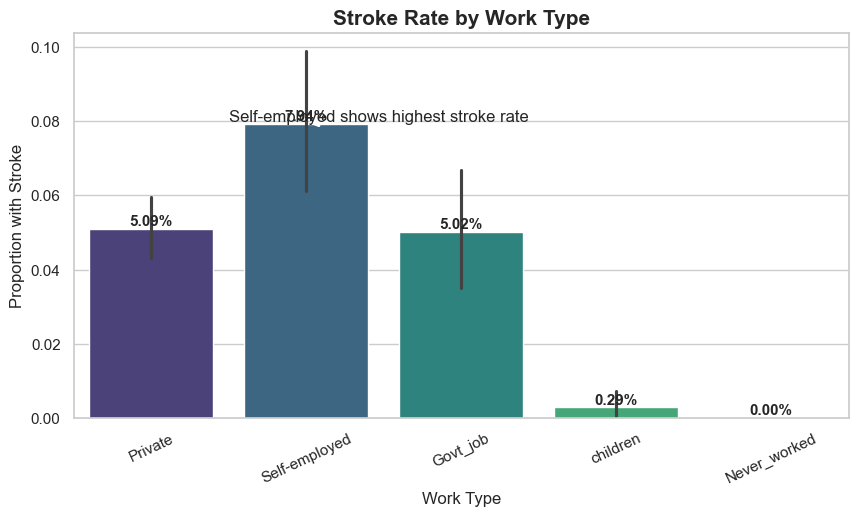

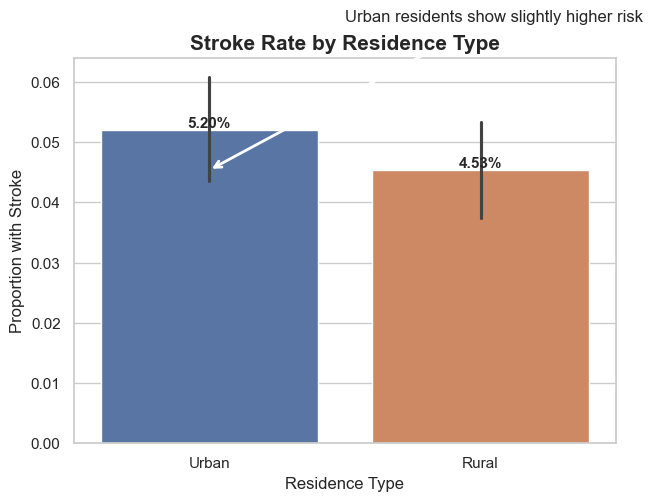

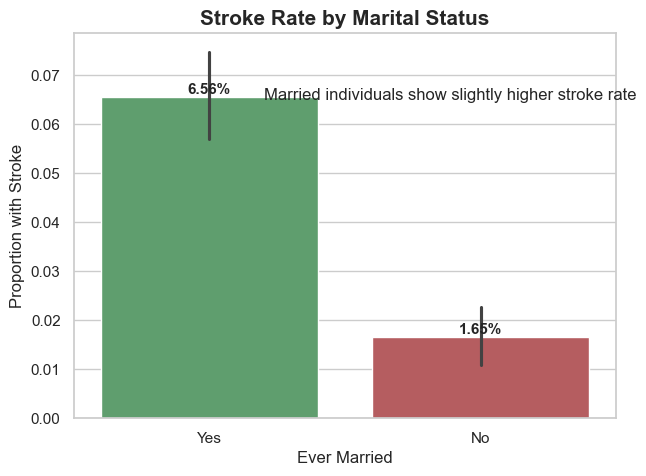

In [32]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# ============================================================
# 1) WORK TYPE
# ============================================================
plt.figure(figsize=(10,5))
ax = sns.barplot(
    x="work_type",
    y="stroke",
    data=df,
    palette="viridis"
)

ax.set_title("Stroke Rate by Work Type", fontsize=15, weight='bold')
ax.set_ylabel("Proportion with Stroke")
ax.set_xlabel("Work Type")
ax.tick_params(axis='x', rotation=25)

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height*100:.2f}%",
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom', fontsize=11, weight='bold')

# Insight annotation
ax.annotate("Self-employed shows highest stroke rate",
            xy=(1, df.groupby("work_type")["stroke"].mean().max()),
            xytext=(0.5, 0.08),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.show()


# ============================================================
# 2) RESIDENCE TYPE
# ============================================================
plt.figure(figsize=(7,5))
ax = sns.barplot(
    x="Residence_type",
    y="stroke",
    data=df,
    palette=["#4C72B0", "#DD8452"]
)

ax.set_title("Stroke Rate by Residence Type", fontsize=15, weight='bold')
ax.set_ylabel("Proportion with Stroke")
ax.set_xlabel("Residence Type")

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height*100:.2f}%",
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom', fontsize=11, weight='bold')

# Insight annotation
ax.annotate("Urban residents show slightly higher risk",
            xy=(0, df.groupby("Residence_type")["stroke"].mean().iloc[0]),
            xytext=(0.5, 0.07),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.show()


# ============================================================
# 3) MARITAL STATUS
# ============================================================
plt.figure(figsize=(7,5))
ax = sns.barplot(
    x="ever_married",
    y="stroke",
    data=df,
    palette=["#55A868", "#C44E52"]
)

ax.set_title("Stroke Rate by Marital Status", fontsize=15, weight='bold')
ax.set_ylabel("Proportion with Stroke")
ax.set_xlabel("Ever Married")

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height*100:.2f}%",
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom', fontsize=11, weight='bold')

# Insight annotation
ax.annotate("Married individuals show slightly higher stroke rate",
            xy=(1, df.groupby("ever_married")["stroke"].mean().iloc[1]),
            xytext=(0.2, 0.065),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.show()


### 4.3 RADAR MAP of Livilyhood Indicators

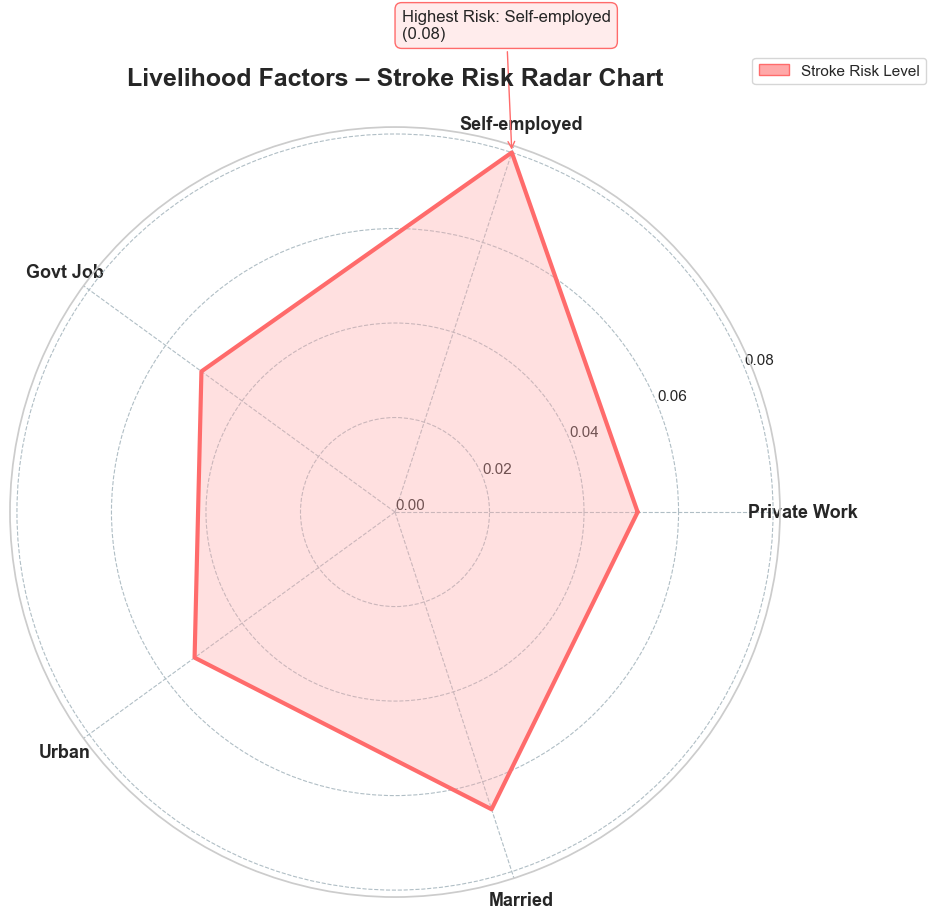

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# --- 1. Compute livelihood stroke risk metrics ---
livelihood_features = {
    "Private Work": df[df.work_type=="Private"].stroke.mean(),
    "Self-employed": df[df.work_type=="Self-employed"].stroke.mean(),
    "Govt Job": df[df.work_type=="Govt_job"].stroke.mean(),
    "Urban": df[df.Residence_type=="Urban"].stroke.mean(),
    "Married": df[df.ever_married=="Yes"].stroke.mean()
}

labels = list(livelihood_features.keys())
values = list(livelihood_features.values())

# Close the loop
values += values[:1]
angles = np.linspace(0, 2*np.pi, len(labels)+1)

# --- 2. Radar Chart Styling ---
plt.figure(figsize=(10,10))
plt.subplot(polar=True)

# Color theme
main_color = "#FF6B6B"        # Coral red
fill_color = "#FFA8A8"        # Soft red
grid_color = "#B0BEC5"        # Muted grey

# Plot
plt.plot(angles, values, color=main_color, linewidth=3)
plt.fill(angles, values, color=fill_color, alpha=0.35)

# --- 3. Aesthetic Improvements ---
plt.xticks(angles[:-1], labels, fontsize=13, fontweight="bold")
plt.yticks(
    np.linspace(0, max(values), 5),
    [f"{x:.2f}" for x in np.linspace(0, max(values), 5)],
    fontsize=11
)
plt.grid(color=grid_color, linestyle="--", linewidth=0.8)

plt.title(
    "Livelihood Factors – Stroke Risk Radar Chart",
    fontsize=18, fontweight="bold", pad=30
)

# --- 4. Insight Callouts ---
max_factor = labels[np.argmax(values)]
max_value = max(values)

plt.annotate(
    f"Highest Risk: {max_factor}\n({max_value:.2f})",
    xy=(angles[np.argmax(values)], max_value),
    xytext=(angles[np.argmax(values)] + 0.3, max_value + 0.02),
    fontsize=12,
    bbox=dict(boxstyle="round,pad=0.4", fc="#FFECEC", ec=main_color),
    arrowprops=dict(arrowstyle="->", color=main_color)
)

# Legend
legend_elements = [
    Patch(facecolor=fill_color, edgecolor=main_color, label="Stroke Risk Level")
]
plt.legend(handles=legend_elements, loc="upper right", bbox_to_anchor=(1.2, 1.1))

plt.show()


### 4.3 Health KPIs vs stroke


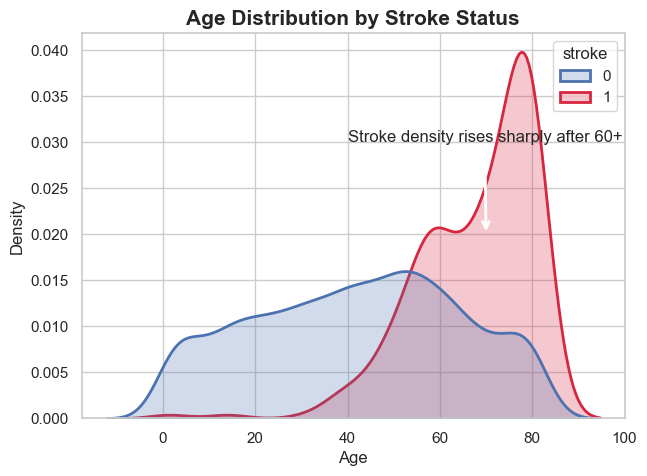

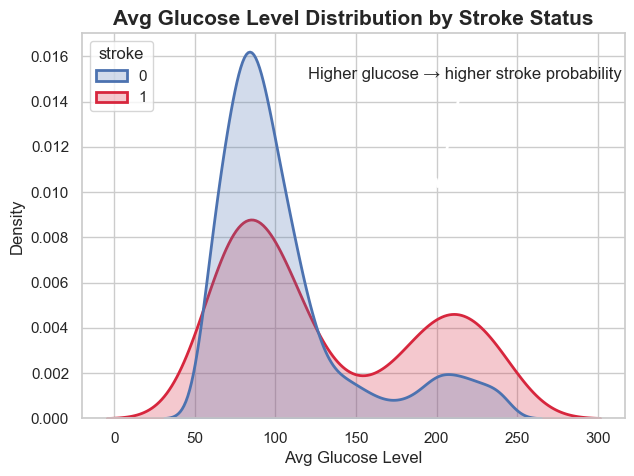

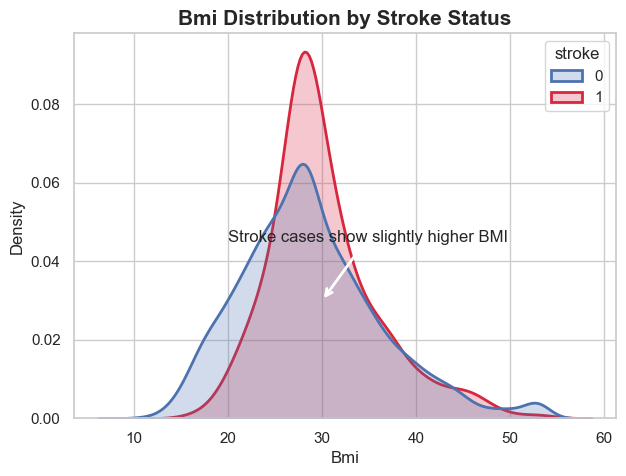

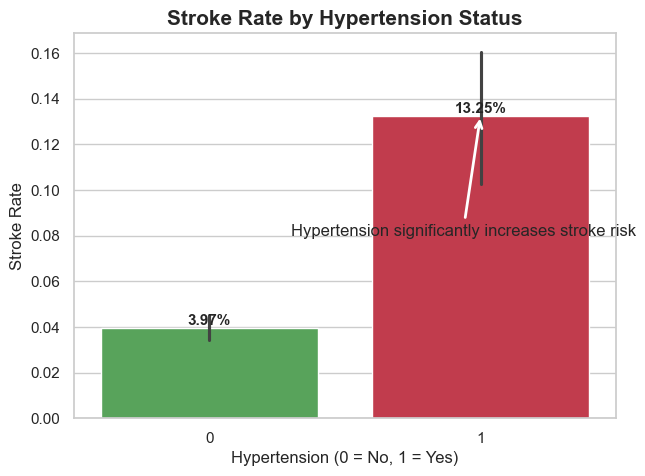

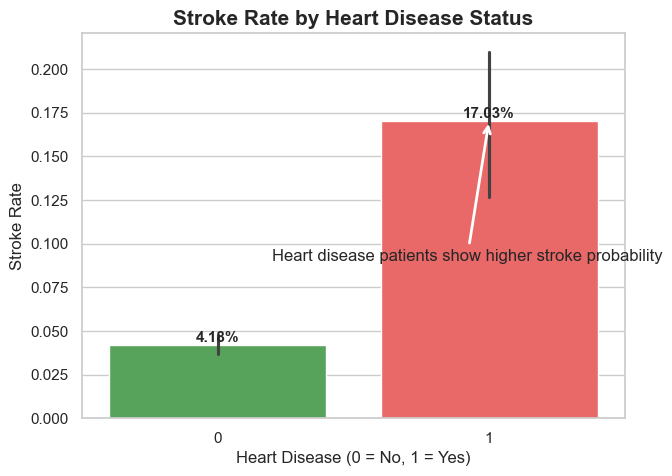

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# ============================================================
# 1) KDE PLOTS — Age, Glucose, BMI by Stroke Status
# ============================================================

for col in ["age", "avg_glucose_level", "bmi"]:
    plt.figure(figsize=(7,5))
    ax = sns.kdeplot(
        data=df,
        x=col,
        hue="stroke",
        fill=True,
        common_norm=False,
        palette=["#4C72B0", "#D7263D"],
        linewidth=2
    )
    
    ax.set_title(f"{col.replace('_',' ').title()} Distribution by Stroke Status",
                 fontsize=15, weight='bold')
    ax.set_xlabel(col.replace('_',' ').title())
    ax.set_ylabel("Density")

    # Insight annotation
    if col == "age":
        ax.annotate("Stroke density rises sharply after 60+",
                    xy=(70, 0.02), xytext=(40, 0.03),
                    arrowprops=dict(arrowstyle="->", lw=2))
    if col == "avg_glucose_level":
        ax.annotate("Higher glucose → higher stroke probability",
                    xy=(200, 0.01), xytext=(120, 0.015),
                    arrowprops=dict(arrowstyle="->", lw=2))
    if col == "bmi":
        ax.annotate("Stroke cases show slightly higher BMI",
                    xy=(30, 0.03), xytext=(20, 0.045),
                    arrowprops=dict(arrowstyle="->", lw=2))

    plt.show()


# ============================================================
# 2) BARPLOT — Hypertension vs Stroke
# ============================================================

plt.figure(figsize=(7,5))
ax = sns.barplot(
    x="hypertension",
    y="stroke",
    data=df,
    palette=["#4CAF50", "#D7263D"]
)

ax.set_title("Stroke Rate by Hypertension Status", fontsize=15, weight='bold')
ax.set_xlabel("Hypertension (0 = No, 1 = Yes)")
ax.set_ylabel("Stroke Rate")

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height*100:.2f}%",
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom', fontsize=11, weight='bold')

ax.annotate("Hypertension significantly increases stroke risk",
            xy=(1, df.groupby("hypertension")["stroke"].mean().iloc[1]),
            xytext=(0.3, 0.08),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.show()


# ============================================================
# 3) BARPLOT — Heart Disease vs Stroke
# ============================================================

plt.figure(figsize=(7,5))
ax = sns.barplot(
    x="heart_disease",
    y="stroke",
    data=df,
    palette=["#4CAF50", "#FF5252"]
)

ax.set_title("Stroke Rate by Heart Disease Status", fontsize=15, weight='bold')
ax.set_xlabel("Heart Disease (0 = No, 1 = Yes)")
ax.set_ylabel("Stroke Rate")

# Add percentage labels
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height*100:.2f}%",
                (p.get_x() + p.get_width()/2, height),
                ha='center', va='bottom', fontsize=11, weight='bold')

ax.annotate("Heart disease patients show higher stroke probability",
            xy=(1, df.groupby("heart_disease")["stroke"].mean().iloc[1]),
            xytext=(0.2, 0.09),
            arrowprops=dict(arrowstyle="->", lw=2))

plt.show()


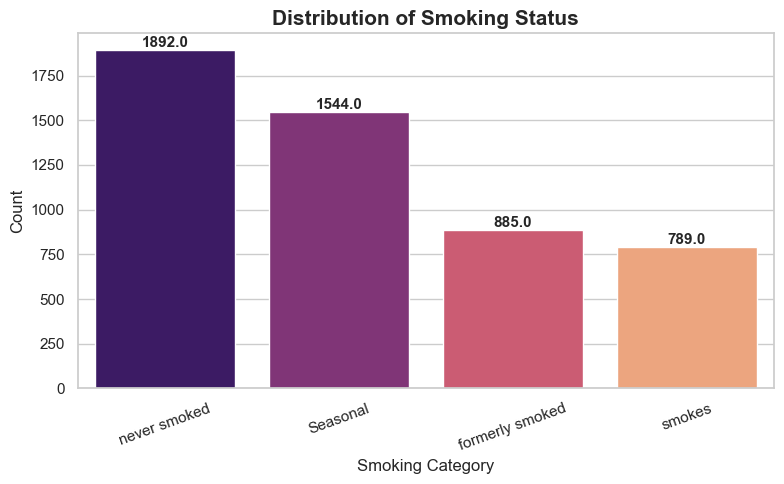

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plt.figure(figsize=(8,5))
ax = sns.countplot(
    x='smoking_status',
    data=df,
    palette='magma',
    order=df['smoking_status'].value_counts().index  # sorts by frequency
)

ax.set_title("Distribution of Smoking Status", fontsize=15, weight='bold')
ax.set_xlabel("Smoking Category")
ax.set_ylabel("Count")
ax.tick_params(axis='x', rotation=20)

# Add count labels on each bar
for p in ax.patches:
    count = p.get_height()
    ax.annotate(
        f"{count}",
        (p.get_x() + p.get_width()/2, count),
        ha='center', va='bottom',
        fontsize=11, weight='bold'
    )

plt.tight_layout()
plt.show()


### 4.4 Smoking Status × Age Group Heatmap

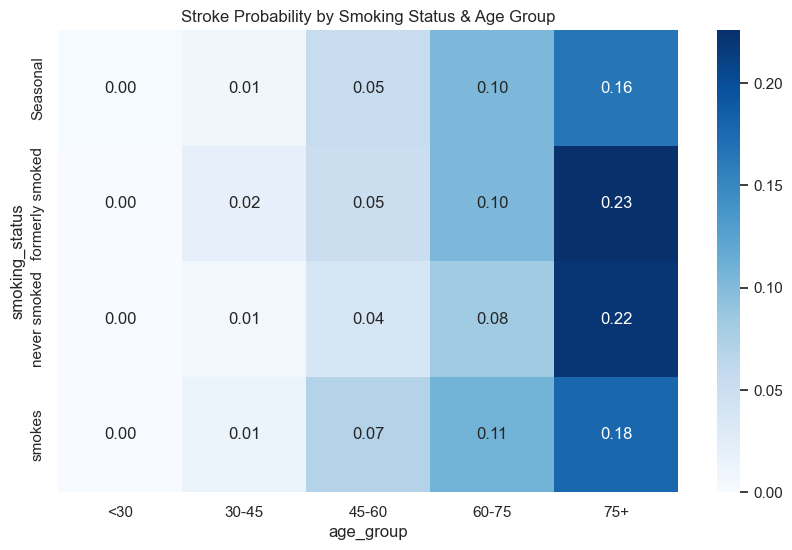

In [36]:
# Smoking Status × Age Group Heatmap

df['age_group'] = pd.cut(df['age'], bins=[0,30,45,60,75,100],
                         labels=["<30","30-45","45-60","60-75","75+"])

pivot2 = df.pivot_table(values='stroke', index='smoking_status', columns='age_group')

plt.figure(figsize=(10,6))
sns.heatmap(pivot2, cmap='Blues', annot=True, fmt=".2f")
plt.title("Stroke Probability by Smoking Status & Age Group")
plt.show()


### 4.5 Correlation heatmap (encoded features)


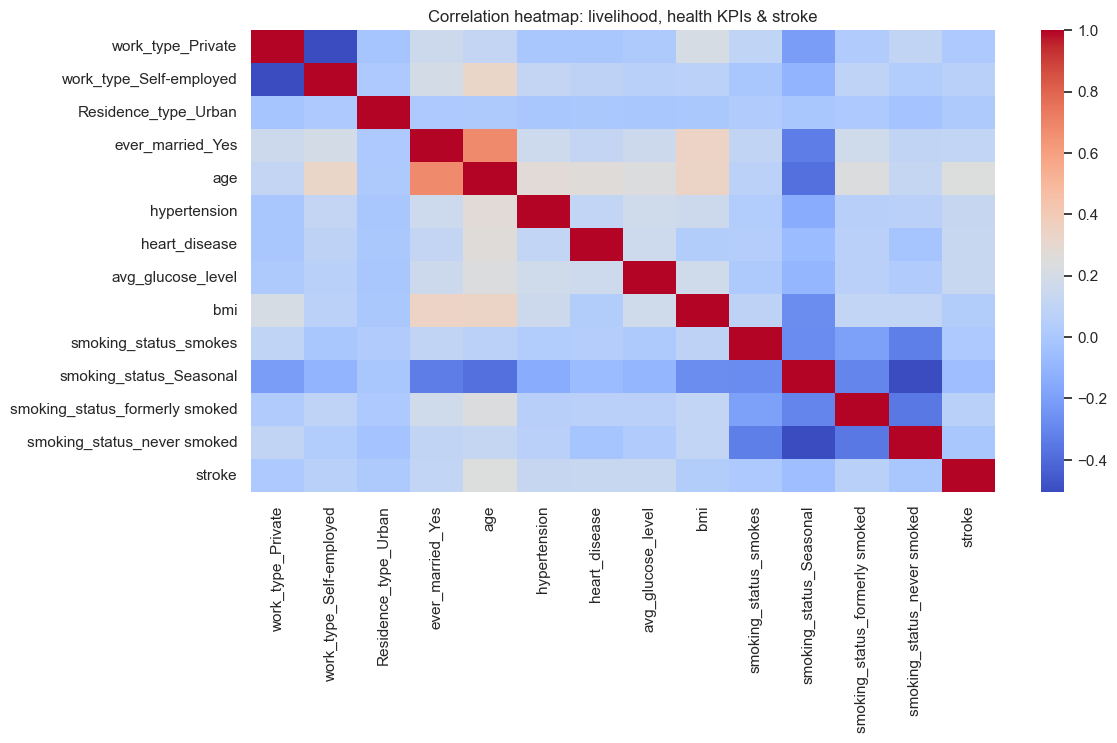

In [37]:
plt.figure(figsize=(12,6))
sns.heatmap(df_encoded[livelihood_cols + health_cols + [target]].corr(),
            cmap="coolwarm", annot=False)
plt.title("Correlation heatmap: livelihood, health KPIs & stroke")
plt.show()


### 4.6 Brain Stroke Dashboard

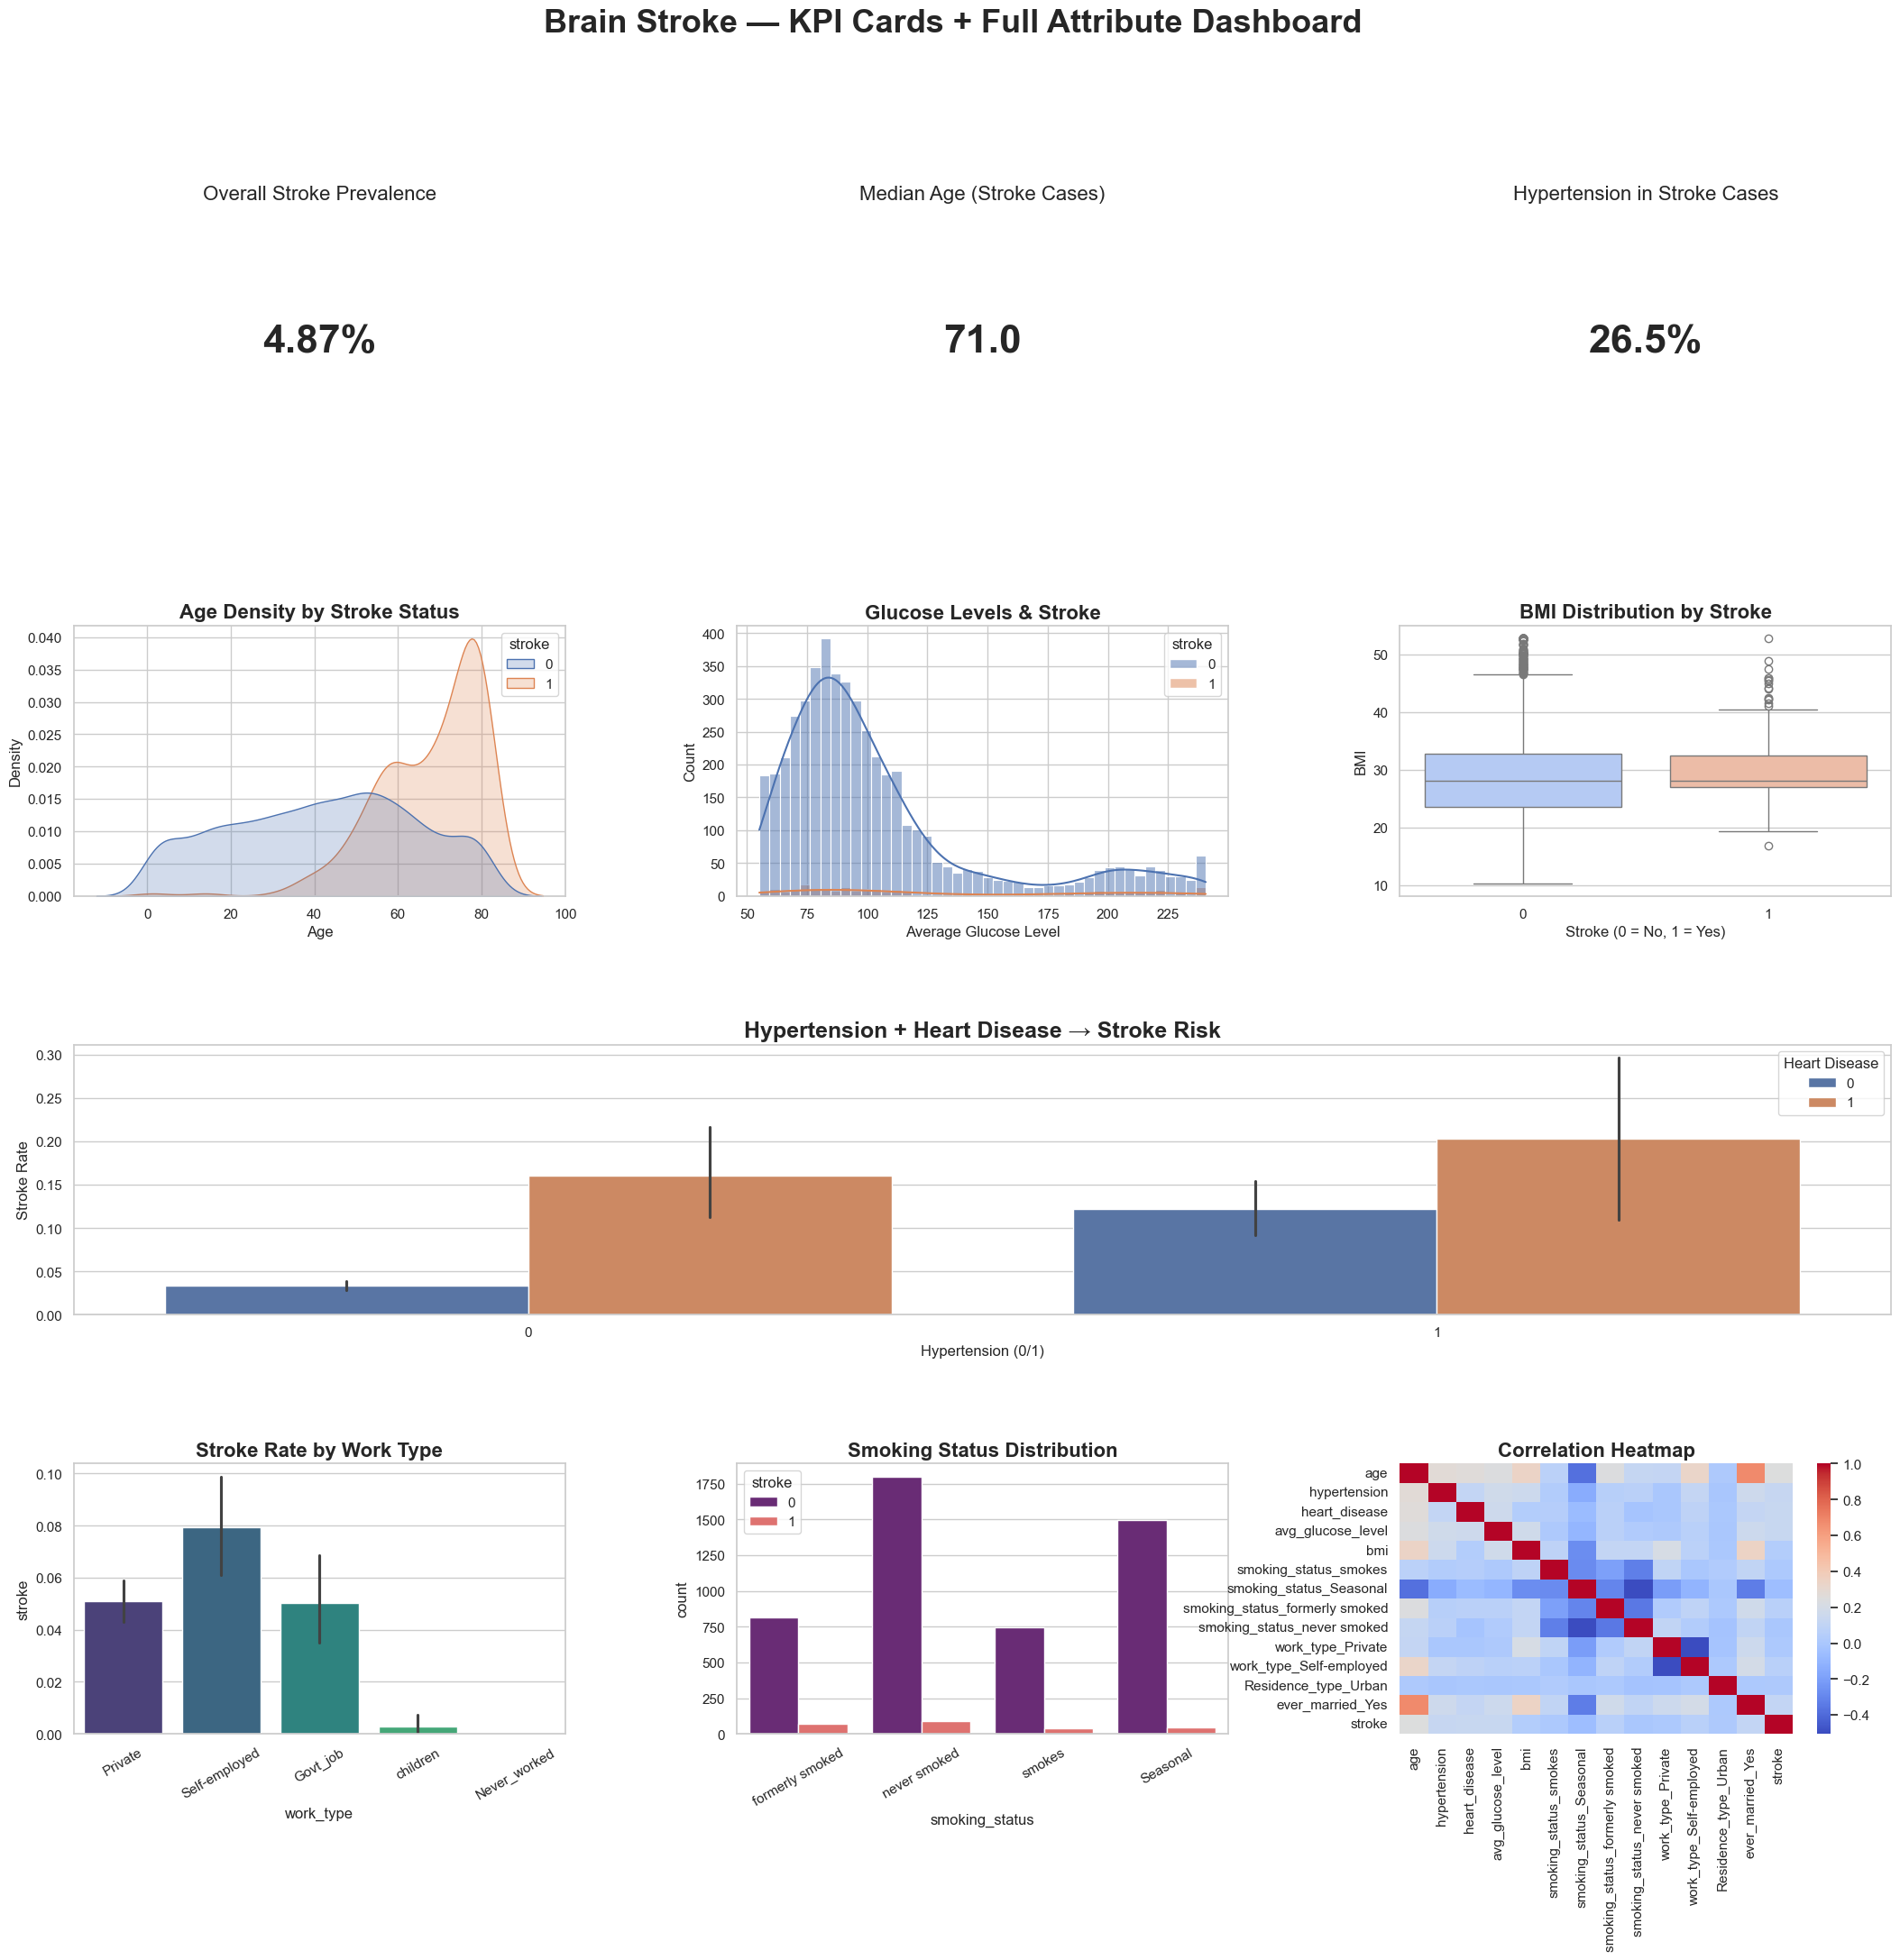

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from matplotlib.gridspec import GridSpec

sns.set(style="whitegrid")

# ---------------------------------------------------
# MASTER FIGURE
# ---------------------------------------------------
fig = plt.figure(figsize=(26, 22))
gs = GridSpec(4, 3, figure=fig, hspace=0.55, wspace=0.35)

# ===================================================
# ROW 0 — KPI INFOGRAPHIC CARDS (3 PANELS)
# ===================================================

# KPI 1 – Stroke prevalence
ax0 = fig.add_subplot(gs[0, 0])
stroke_rate = df['stroke'].mean() * 100
ax0.text(0.5, 0.5, f"{stroke_rate:.2f}%", ha='center', va='center',
         fontsize=32, fontweight='bold')
ax0.set_title("Overall Stroke Prevalence", fontsize=16)
ax0.axis('off')

# KPI 2 – Median Age of Stroke Patients
ax1 = fig.add_subplot(gs[0, 1])
median_age_stroke = df[df.stroke == 1]['age'].median()
ax1.text(0.5, 0.5, f"{median_age_stroke:.1f}", ha='center', va='center',
         fontsize=32, fontweight='bold')
ax1.set_title("Median Age (Stroke Cases)", fontsize=16)
ax1.axis('off')

# KPI 3 – Hypertension share among stroke cases
ax2 = fig.add_subplot(gs[0, 2])
htn_rate = df[df.stroke == 1]['hypertension'].mean() * 100
ax2.text(0.5, 0.5, f"{htn_rate:.1f}%", ha='center', va='center',
         fontsize=32, fontweight='bold')
ax2.set_title("Hypertension in Stroke Cases", fontsize=16)
ax2.axis('off')

# ===================================================
# ROW 1 — AGE, GLUCOSE, BMI PANELS
# ===================================================

# Age KDE
ax3 = fig.add_subplot(gs[1, 0])
sns.kdeplot(data=df, x="age", hue="stroke", fill=True, common_norm=False, ax=ax3)
ax3.set_title("Age Density by Stroke Status", fontsize=16, weight="bold")
ax3.set_xlabel("Age")
ax3.set_ylabel("Density")

# Glucose Histogram
ax4 = fig.add_subplot(gs[1, 1])
sns.histplot(data=df, x="avg_glucose_level", hue="stroke", kde=True, ax=ax4)
ax4.set_title("Glucose Levels & Stroke", fontsize=16, weight="bold")
ax4.set_xlabel("Average Glucose Level")
ax4.set_ylabel("Count")

# BMI Boxplot
ax5 = fig.add_subplot(gs[1, 2])
sns.boxplot(data=df, x="stroke", y="bmi", palette="coolwarm", ax=ax5)
ax5.set_title("BMI Distribution by Stroke", fontsize=16, weight="bold")
ax5.set_xlabel("Stroke (0 = No, 1 = Yes)")
ax5.set_ylabel("BMI")

# ===================================================
# ROW 2 — HYPERTENSION + WORK TYPE + SMOKING
# ===================================================

# Hypertension + Heart Disease
ax6 = fig.add_subplot(gs[2, :])
sns.barplot(data=df, x="hypertension", y="stroke", hue="heart_disease", ax=ax6)
ax6.set_title("Hypertension + Heart Disease → Stroke Risk", fontsize=18, weight="bold")
ax6.set_xlabel("Hypertension (0/1)")
ax6.set_ylabel("Stroke Rate")
ax6.legend(title="Heart Disease")

# ===================================================
# ROW 3 — WORK TYPE, SMOKING, HEATMAP
# ===================================================

# Work Type
ax7 = fig.add_subplot(gs[3, 0])
sns.barplot(data=df, x="work_type", y="stroke", palette="viridis", ax=ax7)
ax7.set_title("Stroke Rate by Work Type", fontsize=16, weight="bold")
ax7.set_xticklabels(ax7.get_xticklabels(), rotation=30)

# Smoking Status
ax8 = fig.add_subplot(gs[3, 1])
sns.countplot(data=df, x="smoking_status", hue="stroke", palette="magma", ax=ax8)
ax8.set_title("Smoking Status Distribution", fontsize=16, weight="bold")
ax8.set_xticklabels(ax8.get_xticklabels(), rotation=30)

# Correlation Heatmap
ax9 = fig.add_subplot(gs[3, 2])
corr = df_encoded[health_cols + livelihood_cols + ["stroke"]].corr()
sns.heatmap(corr, cmap="coolwarm", ax=ax9, cbar=True)
ax9.set_title("Correlation Heatmap", fontsize=16, weight="bold")

# ---------------------------------------------------
plt.suptitle("Brain Stroke — KPI Cards + Full Attribute Dashboard", fontsize=26, weight="bold")
plt.show()


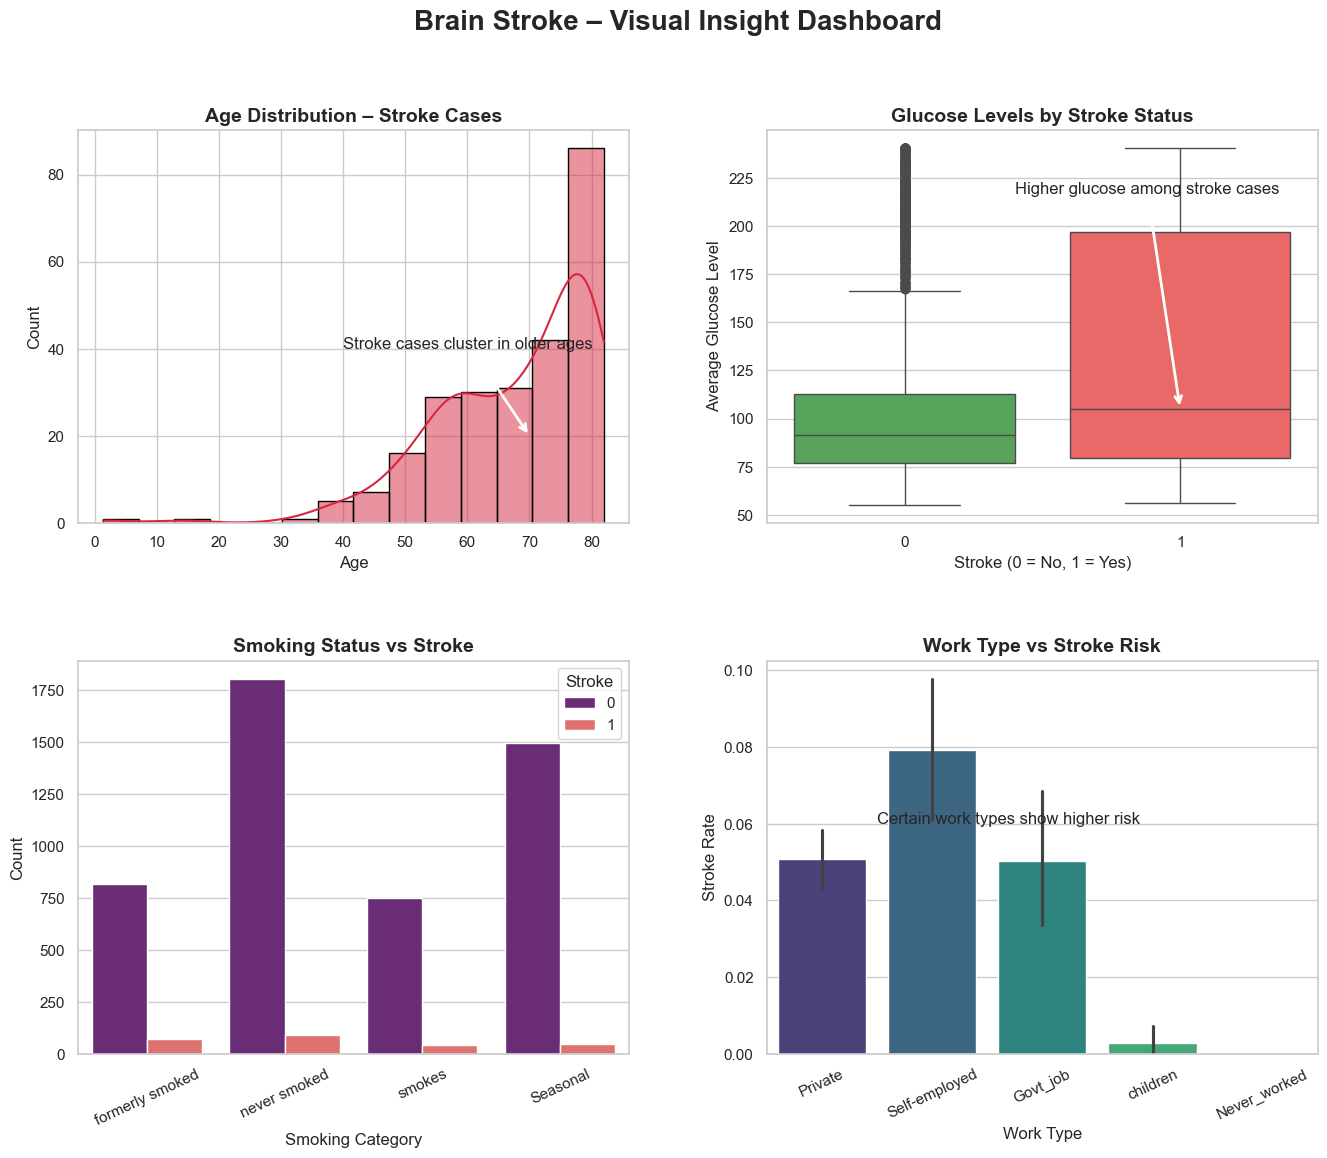

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.35, wspace=0.25)

# ----------------------------------------------------
# PANEL 1 — Age Distribution (Stroke Only)
# ----------------------------------------------------
sns.histplot(
    df[df.stroke == 1]['age'],
    kde=True,
    ax=axes[0,0],
    color='#D7263D',
    edgecolor='black'
)
axes[0,0].set_title("Age Distribution – Stroke Cases", fontsize=14, weight='bold')
axes[0,0].set_xlabel("Age")
axes[0,0].set_ylabel("Count")
axes[0,0].annotate(
    "Stroke cases cluster in older ages",
    xy=(70, 20),
    xytext=(40, 40),
    arrowprops=dict(arrowstyle="->", lw=2)
)

# ----------------------------------------------------
# PANEL 2 — Glucose Levels by Stroke Status
# ----------------------------------------------------
sns.boxplot(
    x='stroke',
    y='avg_glucose_level',
    data=df,
    ax=axes[0,1],
    palette=['#4CAF50', '#FF5252']
)
axes[0,1].set_title("Glucose Levels by Stroke Status", fontsize=14, weight='bold')
axes[0,1].set_xlabel("Stroke (0 = No, 1 = Yes)")
axes[0,1].set_ylabel("Average Glucose Level")
axes[0,1].annotate(
    "Higher glucose among stroke cases",
    xy=(1, df[df.stroke==1]['avg_glucose_level'].median()),
    xytext=(0.4, df['avg_glucose_level'].max()*0.9),
    arrowprops=dict(arrowstyle="->", lw=2)
)

# ----------------------------------------------------
# PANEL 3 — Smoking Status vs Stroke
# ----------------------------------------------------
sns.countplot(
    x='smoking_status',
    hue='stroke',
    data=df,
    ax=axes[1,0],
    palette='magma'
)
axes[1,0].set_title("Smoking Status vs Stroke", fontsize=14, weight='bold')
axes[1,0].set_xlabel("Smoking Category")
axes[1,0].set_ylabel("Count")
axes[1,0].tick_params(axis='x', rotation=25)
axes[1,0].legend(title="Stroke")

# ----------------------------------------------------
# PANEL 4 — Work Type vs Stroke Risk
# ----------------------------------------------------
sns.barplot(
    x='work_type',
    y='stroke',
    data=df,
    ax=axes[1,1],
    palette='viridis'
)
axes[1,1].set_title("Work Type vs Stroke Risk", fontsize=14, weight='bold')
axes[1,1].set_xlabel("Work Type")
axes[1,1].set_ylabel("Stroke Rate")
axes[1,1].tick_params(axis='x', rotation=25)
axes[1,1].annotate(
    "Certain work types show higher risk",
    xy=(2, df.groupby('work_type')['stroke'].mean().max()),
    xytext=(0.5, 0.06),
    arrowprops=dict(arrowstyle="->", lw=2)
)

# ----------------------------------------------------
plt.suptitle("Brain Stroke – Visual Insight Dashboard", fontsize=20, weight='bold')
plt.show()


**Key EDA insights**

- Stroke risk increases sharply with **age**.
- **Hypertension** and **heart disease** are associated with higher stroke rates.
- Higher **avg_glucose_level** and **BMI** show elevated stroke risk.
- Livelihood factors (work_type, residence, marital status) show moderate but visible differences in stroke prevalence.

## PHASE 5 — MODELLING

We use **Logistic Regression** with class balancing:

- Suitable for **binary classification**.
- Provides **interpretable coefficients** (odds ratios) for each KPI.
- `class_weight="balanced"` addresses the strong class imbalance.


In [41]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay

# FIX: Rebuild X and y from the same dataframe
feature_cols = [
    "work_type_Private",
    "work_type_Self-employed",
    "Residence_type_Urban",
    "ever_married_Yes",
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi",
    "smoking_status_smokes",
    "smoking_status_Seasonal",
    "smoking_status_formerly smoked",
    "smoking_status_never smoked"
]

X = df_encoded[feature_cols]
y = df_encoded["stroke"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=500, class_weight="balanced")
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

X shape: (5110, 13)
y shape: (5110,)


## PHASE 6 — EVALUATION


              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022

ROC-AUC: 0.8407407407407407


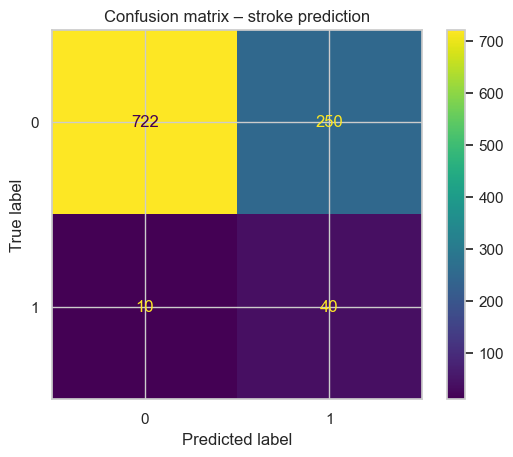

In [42]:
print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion matrix – stroke prediction")
plt.show()


- **ROC‑AUC** summarises overall discrimination.
- Because stroke is rare, **recall for the stroke class** is important (missing a stroke is costly).

## PHASE 7 — FEATURE IMPACT & INSIGHTS


In [43]:
coef_df = pd.DataFrame({
    "feature": X.columns,
    "coef": model.coef_[0]
}).sort_values("coef", key=abs, ascending=False)

coef_df


,feature,coef
5,hypertension,0.596649
12,smoking_status_never smoked,-0.240672
1,work_type_Self-employed,-0.234940
9,smoking_status_smokes,0.231365
6,heart_disease,0.209640
3,ever_married_Yes,-0.208231
2,Residence_type_Urban,0.157420
4,age,0.081244
11,smoking_status_formerly smoked,0.065819
10,smoking_status_Seasonal,-0.058632


### Interpretation (directional)

- Positive coefficient → higher value increases stroke risk.
- Negative coefficient → higher value decreases stroke risk.

We can also visualize feature importance:


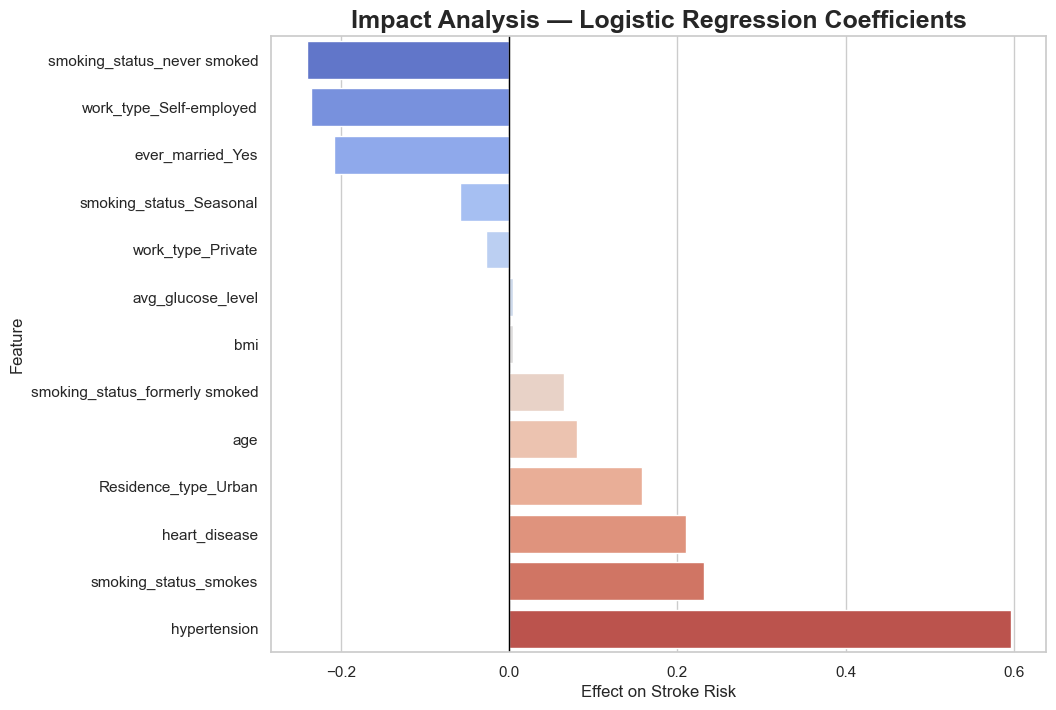

In [44]:
coef_df_sorted = coef_df.sort_values("coef")

plt.figure(figsize=(10, 8))
sns.barplot(x="coef", y="feature", data=coef_df_sorted, palette="coolwarm")
plt.axvline(0, color="black", linewidth=1)
plt.title("Impact Analysis — Logistic Regression Coefficients", fontsize=18, weight="bold")
plt.xlabel("Effect on Stroke Risk")
plt.ylabel("Feature")
plt.show()


**Summary of insights**

- **Age** is the strongest driver of stroke risk.
- **Hypertension** and **heart disease** significantly increase risk.
- Higher **avg_glucose_level** and **BMI** are associated with higher stroke probability.
- Certain **work types** and **urban residence** show moderately higher risk, possibly reflecting lifestyle and stress patterns.

## PHASE 8 — DEPLOYMENT (Prototype & Storytelling)

We build a simple function to estimate stroke risk for a new individual and use it to illustrate risk profiles.


In [46]:
def predict_stroke_risk(model, patient_dict, feature_cols):
    df_new = pd.DataFrame([patient_dict])
    df_new = df_new.reindex(columns=feature_cols, fill_value=0)
    proba = model.predict_proba(df_new)[0][1]
    return proba

sample_patient_high_risk = {
    "age": 67,
    "hypertension": 1,
    "heart_disease": 1,
    "avg_glucose_level": 220,
    "bmi": 35,
    "work_type_Private": 1,
    "work_type_Self-employed": 0,
    "Residence_type_Urban": 1,
    "ever_married_Yes": 1,
    "smoking_status_formerly smoked": 1,
    "smoking_status_smokes": 0
}

sample_patient_low_risk = {
    "age": 35,
    "hypertension": 0,
    "heart_disease": 0,
    "avg_glucose_level": 95,
    "bmi": 22,
    "work_type_Private": 1,
    "work_type_Self-employed": 0,
    "Residence_type_Urban": 0,
    "ever_married_Yes": 0,
    "smoking_status_formerly smoked": 0,
    "smoking_status_smokes": 0
}

print("High‑risk profile – stroke probability:",
      predict_stroke_risk(model, sample_patient_high_risk, X.columns))

print("Low‑risk profile – stroke probability:",
      predict_stroke_risk(model, sample_patient_low_risk, X.columns))


High‑risk profile – stroke probability: 0.8929984637292498
Low‑risk profile – stroke probability: 0.12829586307130478


### Final recommendations for decision‑makers

- **Screening priority:** Older adults with hypertension, heart disease, high glucose and high BMI should be prioritized for regular stroke screening.
- **Lifestyle interventions:** Programs targeting glucose control, weight management and smoking cessation can reduce stroke risk.
- **Livelihood focus:** Urban workers in high‑stress jobs may benefit from targeted wellness and prevention campaigns.